# Explainable and fair credit decisions on HMDA mortgage data: analysis

A lender's model-risk or fair-lending team reviewing a credit decision model asks three questions: how well does
it predict, why does it decide what it decides, and does it treat groups of applicants differently? This notebook
walks through the results of `scripts/run_pipeline.py` on 2025 Arizona home-purchase applications from the public
HMDA data (47,509 conventional, first-lien, owner-occupied, site-built, single-unit applications that were
originated or denied; 7.4% denied).

| Part | Question | Validation |
|---|---|---|
| Data | Is the download complete and correctly parsed? | counts and loan-amount sums against the Data Browser's own aggregation API |
| Models | How well can denial be predicted without protected attributes? | untouched test fold, paired bootstrap, Holm correction |
| Fairness audit | Does the model's risk match each group's observed denial rate, and how do decisions differ? | out-of-fold predictions for every application, bootstrap CIs, Holm correction |
| Mitigation | What does closing a gap cost? | out-of-fold decisions; thresholds fitted on separate validation folds |
| Context | How much of each gap do the reported fields account for? | logistic regression with robust SEs; proxy and ablation checks |
| Explanations | Do SHAP and LIME agree, and does SHAP match the lender's stated reason? | TreeSHAP checked against the `shap` library; LIME against itself with a second seed |

**This is observational data.** HMDA has no credit scores, assets or full credit histories, and race, ethnicity and
sex are reported by applicants (or recorded by visual observation for some in-person applications). Differences
between groups therefore cannot be attributed to discrimination by this analysis, and they cannot be ruled out as
discrimination either.

Everything below reads the tables in `reports/results/`. Data provenance:

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RES, FIG = ROOT / 'reports' / 'results', ROOT / 'reports' / 'figures'
pd.set_option('display.precision', 4)
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.width', 220)
meta = json.loads((RES / 'run_metadata.json').read_text())
{k: meta['data'][k] for k in ['url', 'last_modified', 'sha256_matches', 'raw_rows', 'analysed_rows', 'denied',
                              'denial_rate', 'lenders', 'api_checks', 'api_count_matches']}

{'url': 'https://ffiec.cfpb.gov/v2/data-browser-api/view/csv?states=AZ&years=2025&loan_purposes=1',
 'last_modified': 'Tue, 21 Jul 2026 21:35:41 GMT',
 'sha256_matches': True,
 'raw_rows': 167230,
 'analysed_rows': 47509,
 'denied': 3502,
 'denial_rate': 0.07371234923909153,
 'lenders': 554,
 'api_checks': 34,
 'api_count_matches': 34}

## 1. Data and the cross-check against the official aggregation API

The Data Browser API accepts at most two filter criteria per query, so the pipeline downloads every 2025 Arizona
home-purchase record (167,230 rows, all actions and loan types; the API redirects to a static snapshot file) and
filters locally. To check the download and the parsing, it asks the same API for its own aggregations (record
count and loan-amount sum) by action taken, loan type, lien status, construction method, derived race, derived
ethnicity and derived sex. All 34 category counts and sums match exactly.

The population filter keeps originated (1) and denied (3) applications for conventional, first-lien,
principal-residence, site-built, single-unit purchases, drops records from reporters using the partial exemption
(fields reported as 'Exempt' or code 1111; 192 rows) and drops business-purpose, reverse-mortgage and open-end
records. 'NA' codes are kept as missing values with explicit flags.

Missingness is not innocent here: property value, combined LTV and DTI are 6-16 times more often unreported on
denied applications, because lenders do not always compute them for applications denied early (for example as
incomplete). The flags are model inputs, and the ablation in section 5 measures how much they matter. Fields
that are only reported after a decision (pricing, purchaser, HOEPA status, denial reasons) or that encode the
outcome by construction (pre-approval, initially payable) are excluded; the tables below show the check, the
filter, the missingness by outcome and every excluded field.

In [2]:
chk = pd.read_csv(RES / 'api_crosscheck.csv')
print(f"{int(chk.count_match.sum())} of {len(chk)} category counts match; largest relative loan-amount-sum difference: {chk.sum_rel_diff.max():.2e}")
chk[['dimension', 'value', 'api_count', 'local_count', 'api_loan_amount_sum', 'local_loan_amount_sum']]

34 of 34 category counts match; largest relative loan-amount-sum difference: 0.00e+00


,dimension,value,api_count,local_count,api_loan_amount_sum,local_loan_amount_sum
0,action_taken,1,95029,95029,4.1062e+10,4.1062e+10
1,action_taken,6,31963,31963,1.3398e+10,1.3398e+10
2,action_taken,4,21023,21023,9.0585e+09,9.0585e+09
3,action_taken,3,11691,11691,4.3372e+09,4.3372e+09
4,action_taken,5,3114,3114,9.5631e+08,9.5631e+08
5,action_taken,2,2917,2917,1.2097e+09,1.2097e+09
6,action_taken,8,1263,1263,5.3732e+08,5.3732e+08
7,action_taken,7,230,230,8.2770e+07,8.2770e+07
8,construction_method,1,154617,154617,6.8241e+10,6.8241e+10
9,construction_method,2,12613,12613,2.4013e+09,2.4013e+09


In [3]:
pd.read_csv(RES / 'population_filter.csv')

,step,rows,denied,denial_rate
0,All 2025 Arizona home-purchase records,167230,11691,0.0699
1,Originated (1) or denied (3),106720,11691,0.1095
2,Conventional loan,69248,7966,0.1150
3,First lien,64918,7095,0.1093
4,Principal residence,52887,5862,0.1108
5,Site-built,48393,3720,0.0769
6,Single unit,48192,3678,0.0763
7,Not partially exempt (no 'Exempt' / 1111 codes),48000,3665,0.0764
8,"Not business purpose, reverse mortgage or open-end line",47509,3502,0.0737


In [4]:
pd.read_csv(RES / 'missingness_by_outcome.csv')

,field,missing_approved,missing_denied,denial_rate_if_missing,denial_rate_if_present,n_missing
0,property_value_k,0.0057,0.0894,0.5550,0.0679,564
1,cltv,0.0062,0.0674,0.4627,0.0695,510
2,income_k,0.0112,0.0163,0.1040,0.0734,548
3,dti,0.0100,0.0651,0.3403,0.0699,670
4,loan_term,0.0004,0.0083,0.6444,0.0732,45
5,tract_income_pct,0.0007,0.0286,0.7634,0.0718,131


In [5]:
pd.read_csv(RES / 'excluded_fields.csv')

,field,reason
0,derived_race / applicant & co-applicant race,protected attribute (audit only)
1,derived_ethnicity / applicant & co-applicant ethnicity,protected attribute (audit only)
2,derived_sex / applicant & co-applicant sex,protected attribute (audit only)
3,"applicant_age, co-applicant_age, *_age_above_62",protected attribute (audit only)
4,*_observed (race/ethnicity/sex collected by visual observation),protected-attribute metadata
5,tract_minority_population_percent,close geographic proxy for race (audit only)
6,"interest_rate, rate_spread, total_loan_costs, origination_charges, discount_...","pricing fields, only reported for originated loans (outcome leak)"
7,hoepa_status,'not applicable' (3) for every denial (outcome leak)
8,purchaser_type,0 (not sold) for every denial (outcome leak)
9,denial_reason-1..4,"reported only for denials; used to validate explanations, never as a feature"


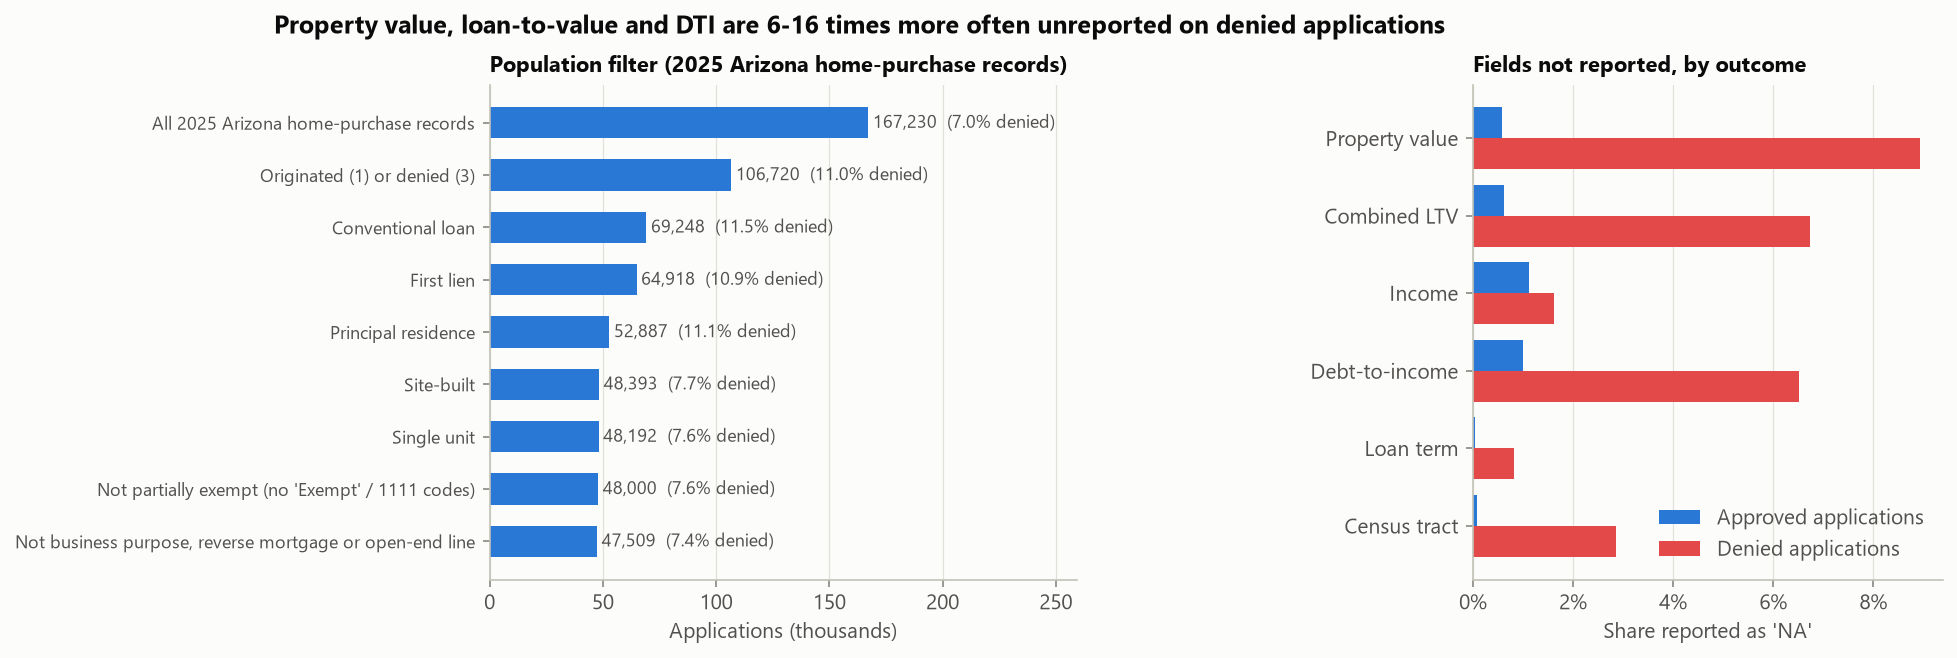

In [6]:
display(Image(FIG / '00_data.png'))

## 2. Predicting denial without protected attributes

Applications are split into five folds stratified by outcome and race group. Rotation 0 (training folds 2-4,
validation fold 1, test fold 0) is used to tune and compare models: a DTI lookup baseline, logistic regression with
splines for DTI and CLTV, and LightGBM / XGBoost / CatBoost tuned with Optuna on validation log loss (30, 20 and 10
trials). Log loss is a proper scoring rule, so the tuned models stay calibrated, which matters for the
within-group calibration check below. The test fold (9,502 applications, 701 denied) is used only once.

The three gradient-boosting models beat the spline logistic regression on every metric (ROC AUC +0.024 to +0.028,
AP +0.061 to +0.069, Holm-adjusted p = 0.018, the smallest value 1,000 bootstrap resamples can give after
correction); among themselves the differences are small and not significant. All are well calibrated (ECE at most
0.007). LightGBM is used for everything that follows.

In [7]:
res = pd.read_csv(RES / 'model_results.csv')
res[['model', 'val_log_loss', 'roc_auc', 'roc_auc_ci_low', 'roc_auc_ci_high', 'ap', 'ap_ci_low', 'ap_ci_high',
     'brier', 'log_loss', 'ece', 'flagged_share', 'accuracy', 'denial_recall', 'denial_precision']]

,model,val_log_loss,roc_auc,roc_auc_ci_low,roc_auc_ci_high,ap,ap_ci_low,ap_ci_high,brier,log_loss,ece,flagged_share,accuracy,denial_recall,denial_precision
0,DTI lookup,0.1814,0.7527,0.7317,0.7753,0.4698,0.4312,0.5069,0.0465,0.1908,0.0065,0.0466,0.9434,0.4322,0.6840
1,Logistic regression,0.1619,0.8623,0.8453,0.8783,0.6067,0.5696,0.6432,0.0410,0.1640,0.0052,0.0416,0.9531,0.4636,0.8228
2,LightGBM,0.1468,0.8900,0.8754,0.9041,0.6676,0.6353,0.7006,0.0372,0.1483,0.0065,0.0399,0.9571,0.4793,0.8865
3,XGBoost,0.1462,0.8877,0.8730,0.9024,0.6678,0.6362,0.7000,0.0371,0.1487,0.0048,0.0423,0.9574,0.4979,0.8682
4,CatBoost,0.1469,0.8862,0.8713,0.9007,0.6759,0.6426,0.7085,0.0369,0.1481,0.0072,0.0409,0.9571,0.4864,0.8766


In [8]:
pd.read_csv(RES / 'model_significance.csv')

,model,metric,diff,diff_ci_low,diff_ci_high,p_value,reference,p_holm
0,DTI lookup,roc_auc,-0.1096,-0.1301,-0.0888,0.001,Logistic regression,0.018
1,DTI lookup,ap,-0.1370,-0.1592,-0.1151,0.001,Logistic regression,0.018
2,DTI lookup,log_loss,0.0268,0.0217,0.0322,0.001,Logistic regression,0.018
3,LightGBM,roc_auc,0.0277,0.0172,0.0382,0.001,Logistic regression,0.018
4,LightGBM,ap,0.0609,0.0435,0.0798,0.001,Logistic regression,0.018
5,LightGBM,log_loss,-0.0156,-0.0195,-0.0119,0.001,Logistic regression,0.018
6,XGBoost,roc_auc,0.0253,0.0147,0.0362,0.001,Logistic regression,0.018
7,XGBoost,ap,0.0611,0.0430,0.0816,0.001,Logistic regression,0.018
8,XGBoost,log_loss,-0.0153,-0.0193,-0.0114,0.001,Logistic regression,0.018
9,CatBoost,roc_auc,0.0239,0.0128,0.0350,0.001,Logistic regression,0.018


In [9]:
pd.read_csv(RES / 'tuned_models.csv')

,model,trials,val_log_loss,best_iteration,tuning_seconds,params
0,Logistic regression,4,0.1619,0,0.6055,"{""C"": 10.0}"
1,LightGBM,30,0.1468,310,15.6359,"{""objective"": ""binary"", ""metric"": ""binary_logloss"", ""num_threads"": 2, ""seed""..."
2,XGBoost,20,0.1462,304,17.8850,"{""objective"": ""binary:logistic"", ""eval_metric"": ""logloss"", ""tree_method"": ""h..."
3,CatBoost,10,0.1469,479,182.2870,"{""iterations"": 1500, ""loss_function"": ""Logloss"", ""od_type"": ""Iter"", ""od_wait..."


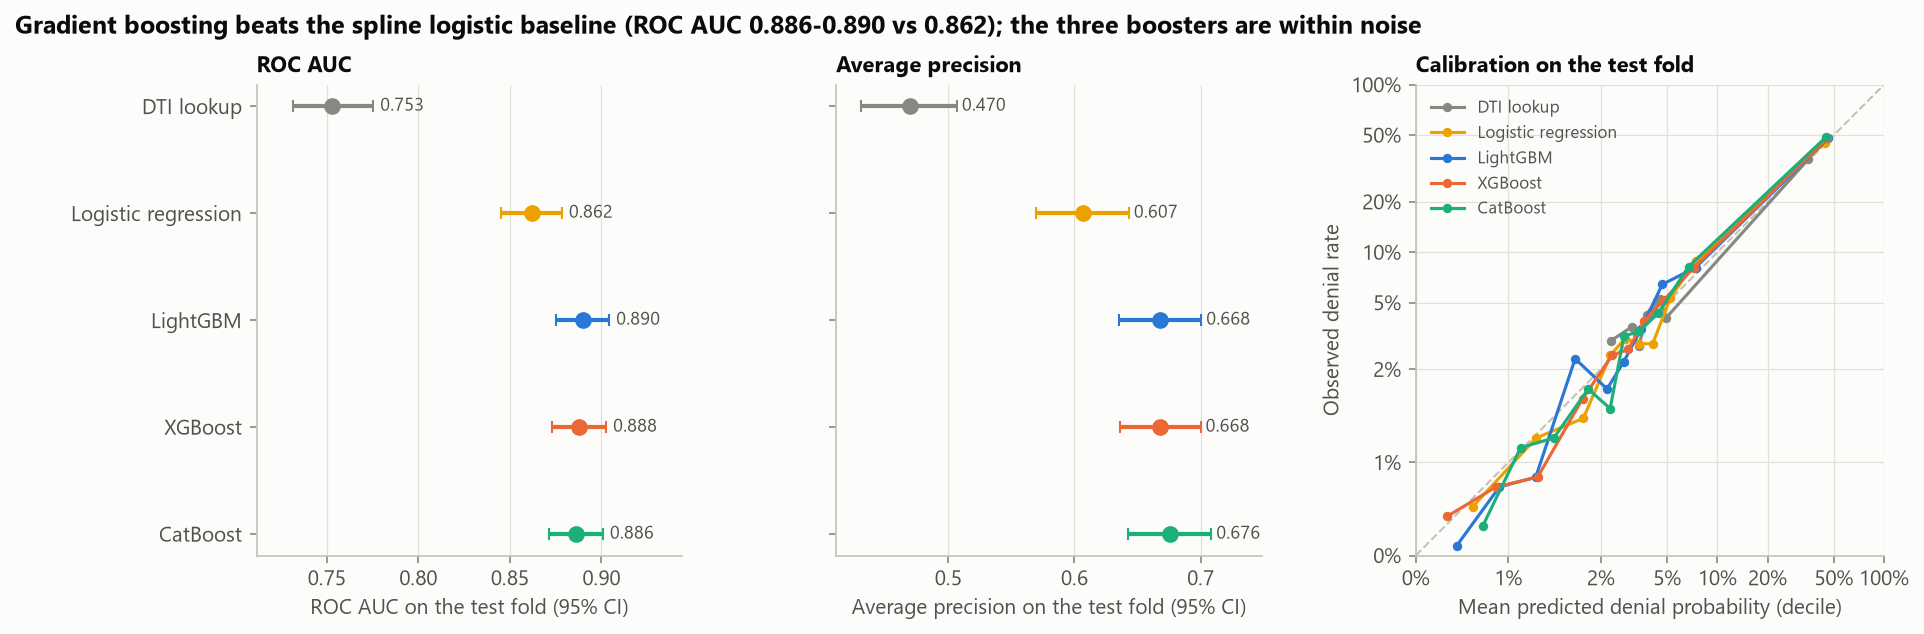

In [10]:
display(Image(FIG / '02_model_comparison.png'))

## 3. Fairness audit of the unaware model

The tuned LightGBM configuration is refit in all five rotations, so every application is scored by a model that
never saw it (out-of-fold AUC 0.879). Protected attributes are never model inputs; they are used here only to group
the predictions.

**Within-group calibration.** For each group, the observed denial rate is compared with the mean predicted denial
probability. The model reproduces the denial rate of Black applicants (13.3% observed, 12.9% predicted) and of White
applicants (6.8% vs 6.9%), but under-predicts denials for American Indian / Alaska Native (15.4% vs 11.1%), Hispanic
or Latino (11.7% vs 10.6%) and Asian (8.8% vs 7.7%) applicants. These gaps survive Holm correction over the 22
groups with at least 150 applications. A gap means that applicants in the group are denied more often than
applicants with the same reported fields in other groups; HMDA cannot say whether unreported factors such as
credit scores or discrimination explain it.

In [11]:
pd.read_csv(RES / 'crossfit_rotations.csv')

,rotation,best_iteration,best_iteration_reweighed,threshold,threshold_reweighed,test_auc
0,0,310,311,0.5074,0.5931,0.8900
1,1,217,238,0.5448,0.5593,0.8796
2,2,216,342,0.5700,0.4772,0.8688
3,3,309,263,0.5199,0.4200,0.8788
4,4,397,365,0.4706,0.5087,0.8756


In [12]:
audit = pd.read_csv(RES / 'fairness_audit.csv')
audit[['attribute', 'group', 'n', 'n_denied', 'observed_denial_rate', 'mean_predicted', 'calibration_gap',
       'calibration_gap_ci_low', 'calibration_gap_ci_high', 'roc_auc', 'ece']]

,attribute,group,n,n_denied,observed_denial_rate,mean_predicted,calibration_gap,calibration_gap_ci_low,calibration_gap_ci_high,roc_auc,ece
0,race,White,33451,2289,0.0684,0.0692,-0.0008,-2.7523e-03,0.0012,0.8757,0.0016
1,race,Not available,7923,645,0.0814,0.0755,0.0059,1.7587e-03,0.0106,0.8760,0.0064
2,race,Asian,3397,298,0.0877,0.0769,0.0108,4.6435e-03,0.0169,0.8848,0.0109
3,race,Joint (two races),1333,77,0.0578,0.0602,-0.0024,-1.1062e-02,0.0066,0.9006,0.0043
4,race,Black,893,119,0.1333,0.1288,0.0044,-1.0457e-02,0.0192,0.8982,0.0155
5,race,American Indian / Alaska Native,337,52,0.1543,0.1105,0.0438,1.6029e-02,0.0738,0.8725,0.0438
6,race,Other minority races,175,22,0.1257,0.1028,0.0229,-1.1901e-02,0.0639,0.9174,0.0318
7,ethnicity,Not Hispanic or Latino,30623,1949,0.0636,0.0650,-0.0014,-3.3664e-03,0.0006,0.8824,0.0014
8,ethnicity,Hispanic or Latino,7475,874,0.1169,0.1062,0.0107,5.4218e-03,0.0161,0.8568,0.0107
9,ethnicity,Not available,7300,562,0.0770,0.0699,0.0071,2.6977e-03,0.0117,0.8677,0.0074


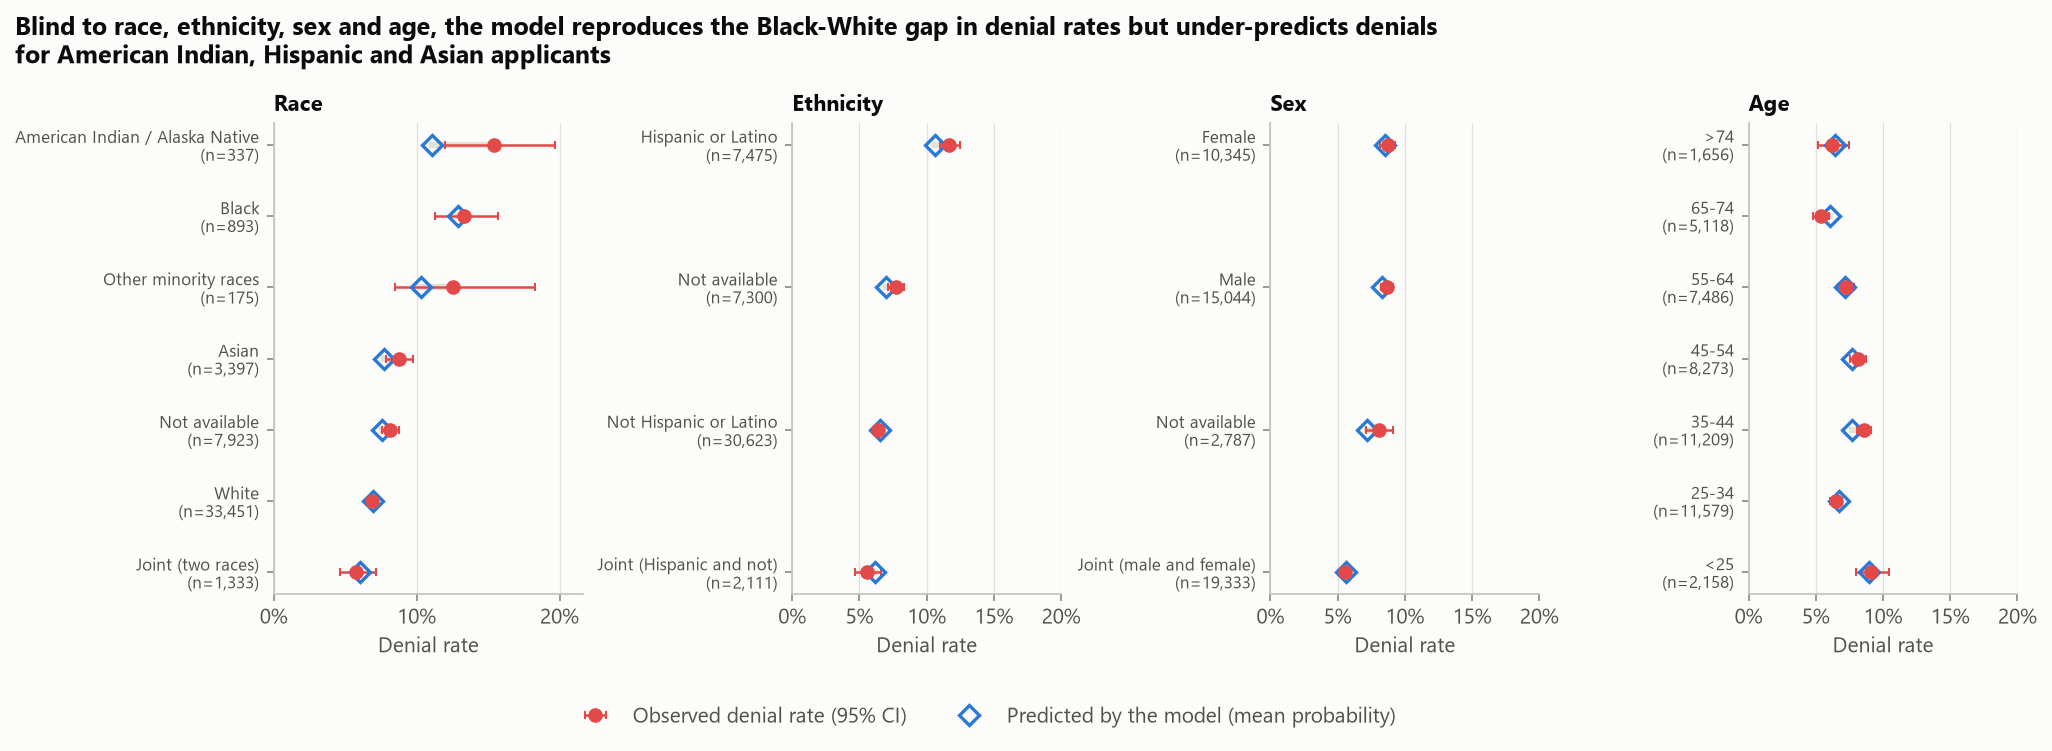

In [13]:
display(Image(FIG / '01_observed_vs_predicted.png'))

In [14]:
audit[['attribute', 'group', 'n', 'model_approval_rate', 'model_approval_rate_diff',
       'model_approval_rate_diff_ci_low', 'model_approval_rate_diff_ci_high', 'true_approval_rate',
       'true_approval_rate_diff', 'true_approval_rate_diff_ci_low', 'true_approval_rate_diff_ci_high']]

,attribute,group,n,model_approval_rate,model_approval_rate_diff,model_approval_rate_diff_ci_low,model_approval_rate_diff_ci_high,true_approval_rate,true_approval_rate_diff,true_approval_rate_diff_ci_low,true_approval_rate_diff_ci_high
0,race,White,33451,0.9626,0.0000,0.0000,0.0000,0.9956,0.0000e+00,0.0000,0.0000
1,race,Not available,7923,0.9553,-0.0073,-0.0125,-0.0024,0.9955,-1.6992e-04,-0.0020,0.0016
2,race,Asian,3397,0.9520,-0.0106,-0.0177,-0.0032,0.9984,2.7509e-03,0.0011,0.0041
3,race,Joint (two races),1333,0.9662,0.0036,-0.0069,0.0129,0.9952,-4.1278e-04,-0.0044,0.0032
4,race,Black,893,0.9093,-0.0533,-0.0731,-0.0356,0.9897,-5.9716e-03,-0.0140,0.0006
5,race,American Indian / Alaska Native,337,0.9288,-0.0338,-0.0631,-0.0069,0.9965,8.5552e-04,-0.0067,0.0048
6,race,Other minority races,175,0.9314,-0.0312,-0.0706,0.0036,0.9869,-8.7076e-03,-0.0283,0.0047
7,ethnicity,Not Hispanic or Latino,30623,0.9648,0.0000,0.0000,0.0000,0.9960,0.0000e+00,0.0000,0.0000
8,ethnicity,Hispanic or Latino,7475,0.9357,-0.0291,-0.0351,-0.0234,0.9942,-1.7810e-03,-0.0038,0.0001
9,ethnicity,Not available,7300,0.9600,-0.0048,-0.0099,-0.0001,0.9954,-6.2504e-04,-0.0025,0.0011


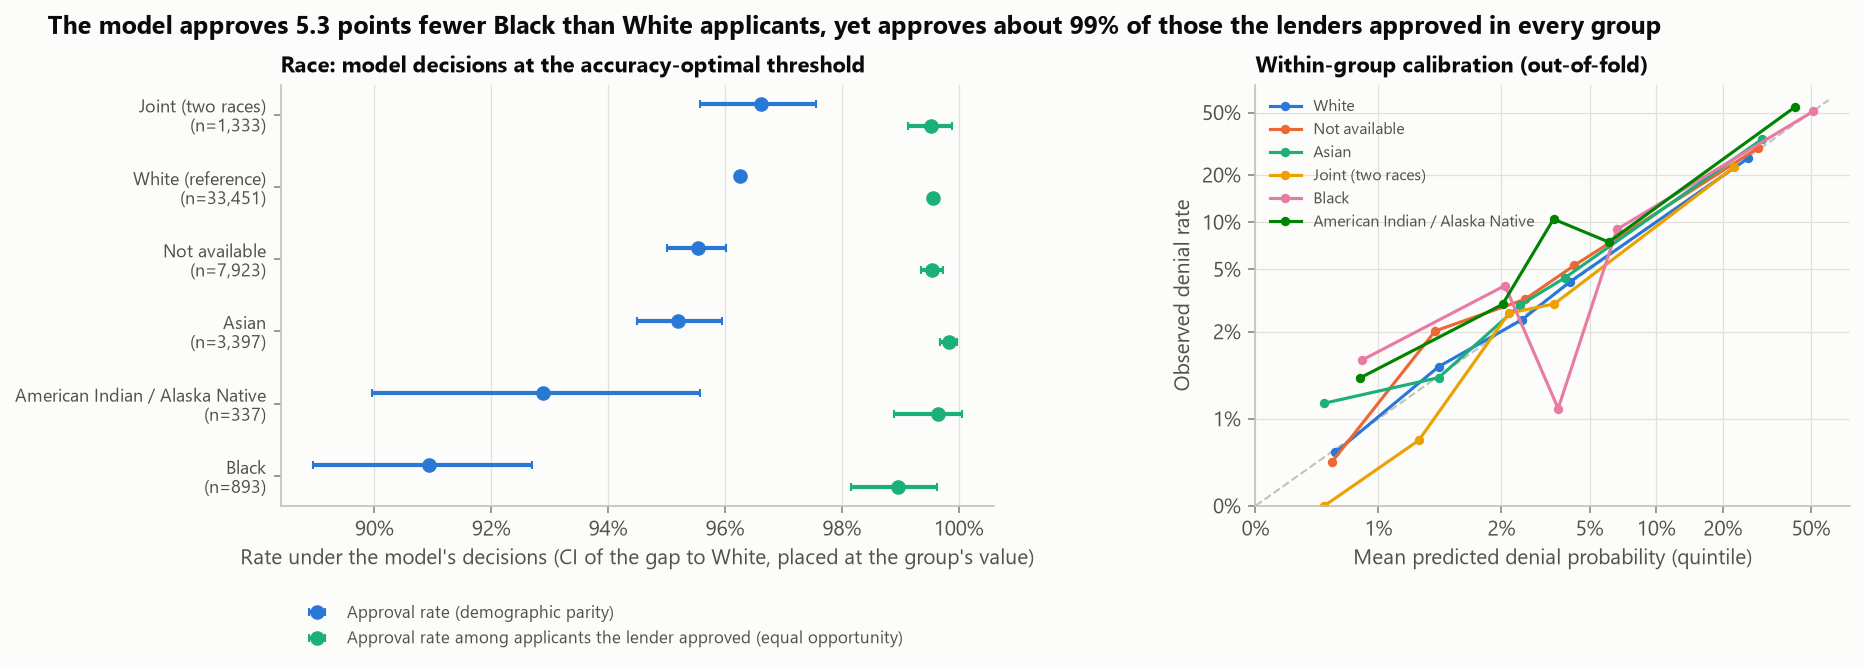

In [15]:
display(Image(FIG / '06_fairness_audit.png'))

## 4. Decisions, fairness metrics and mitigation

Decisions use a single threshold per rotation chosen on the validation fold to maximise accuracy (0.47-0.57). At
that threshold the model approves 90.9% of Black and 96.3% of White applicants (demographic parity gap 5.3 points),
yet approves 99.0% and 99.6% of the applicants the lenders approved (equal opportunity gap 0.6 points, CI includes
zero). With different base rates and a calibrated score, both criteria cannot hold at once.

Mitigation is evaluated out-of-fold with race as the sensitive attribute:

- **Reweighing** (Kamiran and Calders): training weights that make race and outcome independent. Because race is
  not an input, the weights barely change the fitted model, and the gaps stay where they were.
- **fairlearn ThresholdOptimizer**, fitted on each rotation's validation fold: demographic parity cuts the race
  approval gap from 5.7 to 1.0 points for 0.2 points of accuracy (denial precision 90.1% -> 87.7%), but widens the
  equal opportunity gap from 0.9 to 1.7 points. The equal-opportunity version has almost nothing to fix and,
  fitted on small validation groups, makes both gaps worse out of fold.

Group-specific thresholds use race at decision time. US fair-lending law (ECOA / Regulation B and the Fair Housing
Act) generally does not allow that for credit decisions, so this is shown only to size the trade-off.

In [16]:
mit = pd.read_csv(RES / 'mitigation_results.csv')
mit[['method', 'accuracy', 'accuracy_ci_low', 'accuracy_ci_high', 'balanced_accuracy', 'denial_recall',
     'denial_precision', 'approval_rate', 'roc_auc', 'race_dp_difference', 'dp_ci_low', 'dp_ci_high',
     'dp_gap_groups', 'race_eo_difference', 'eo_ci_low', 'eo_ci_high', 'eo_gap_groups']]

,method,accuracy,accuracy_ci_low,accuracy_ci_high,balanced_accuracy,denial_recall,denial_precision,approval_rate,roc_auc,race_dp_difference,dp_ci_low,dp_ci_high,dp_gap_groups,race_eo_difference,eo_ci_low,eo_ci_high,eo_gap_groups
0,Baseline (unaware),0.9588,0.9571,0.9605,0.7460,0.4963,0.9010,0.9594,0.8785,0.0569,0.0343,0.0790,Joint (two races) - Black,0.0087,0.0016,0.0166,Asian - Black
1,Reweighing,0.9587,0.9569,0.9603,0.7463,0.4971,0.8960,0.9591,0.8791,0.0611,0.0383,0.0828,Joint (two races) - Black,0.0110,0.0037,0.0195,Asian - Black
2,Group thresholds: demographic parity,0.9567,0.9549,0.9584,0.7375,0.4803,0.8774,0.9597,NaN,0.0096,-0.0042,0.0266,White - Black,0.0166,0.0046,0.0322,Asian - American Indian / Alaska Native
3,Group thresholds: equal opportunity,0.9578,0.9559,0.9595,0.7434,0.4920,0.8845,0.9590,NaN,0.0612,0.0305,0.0968,Joint (two races) - American Indian / Alaska Native,0.0236,0.0067,0.0428,White - American Indian / Alaska Native


In [17]:
mit[['method'] + [f'{a}_{m}' for a in ['ethnicity', 'sex', 'age'] for m in ['dp_difference', 'eo_difference']]]

,method,ethnicity_dp_difference,ethnicity_eo_difference,sex_dp_difference,sex_eo_difference,age_dp_difference,age_eo_difference
0,Baseline (unaware),0.0291,0.0018,0.0199,0.0019,0.0161,0.0031
1,Reweighing,0.0294,0.0028,0.0197,0.0020,0.0163,0.0037
2,Group thresholds: demographic parity,0.0297,0.0045,0.0181,0.0027,0.0156,0.0041
3,Group thresholds: equal opportunity,0.0295,0.0028,0.0200,0.0027,0.0148,0.0031


In [18]:
g = pd.read_csv(RES / 'mitigation_by_group.csv')
g[(g.attribute == 'race') & (g.n >= 300)].pivot_table(index='group', columns='method', values='approval_rate').round(4)

method,Baseline (unaware),Group thresholds: demographic parity,Group thresholds: equal opportunity,Reweighing
group,,,,
American Indian / Alaska Native,0.9288,0.9525,0.9050,0.9288
Asian,0.9520,0.9582,0.9461,0.9517
Black,0.9093,0.9507,0.9138,0.9059
Joint (two races),0.9662,0.9572,0.9662,0.9670
Not available,0.9553,0.9594,0.9549,0.9556
White,0.9626,0.9603,0.9628,0.9623


In [19]:
rules = pd.read_csv(RES / 'threshold_rules.csv')
rules[rules.rotation == 0]

,rotation,method,group,p0,threshold0,p1,threshold1
0,0,Group thresholds: demographic parity,American Indian / Alaska Native,0.5304,0.5008,0.4696,-inf
1,0,Group thresholds: demographic parity,Asian,0.8117,0.4687,0.1883,0.0108
2,0,Group thresholds: demographic parity,Black,0.6311,0.0942,0.3689,-inf
3,0,Group thresholds: demographic parity,Joint (two races),0.0301,0.9351,0.9699,0.8215
4,0,Group thresholds: demographic parity,Not available,0.5851,0.2888,0.4149,0.1278
5,0,Group thresholds: demographic parity,Other minority races,0.0456,0.9514,0.9544,0.2511
6,0,Group thresholds: demographic parity,White,0.9637,0.5604,0.0363,0.3757
7,0,Group thresholds: equal opportunity,American Indian / Alaska Native,0.1710,0.7789,0.8290,0.5008
8,0,Group thresholds: equal opportunity,Asian,0.3714,0.8345,0.6286,0.4687
9,0,Group thresholds: equal opportunity,Black,0.4620,0.1544,0.5380,0.1061


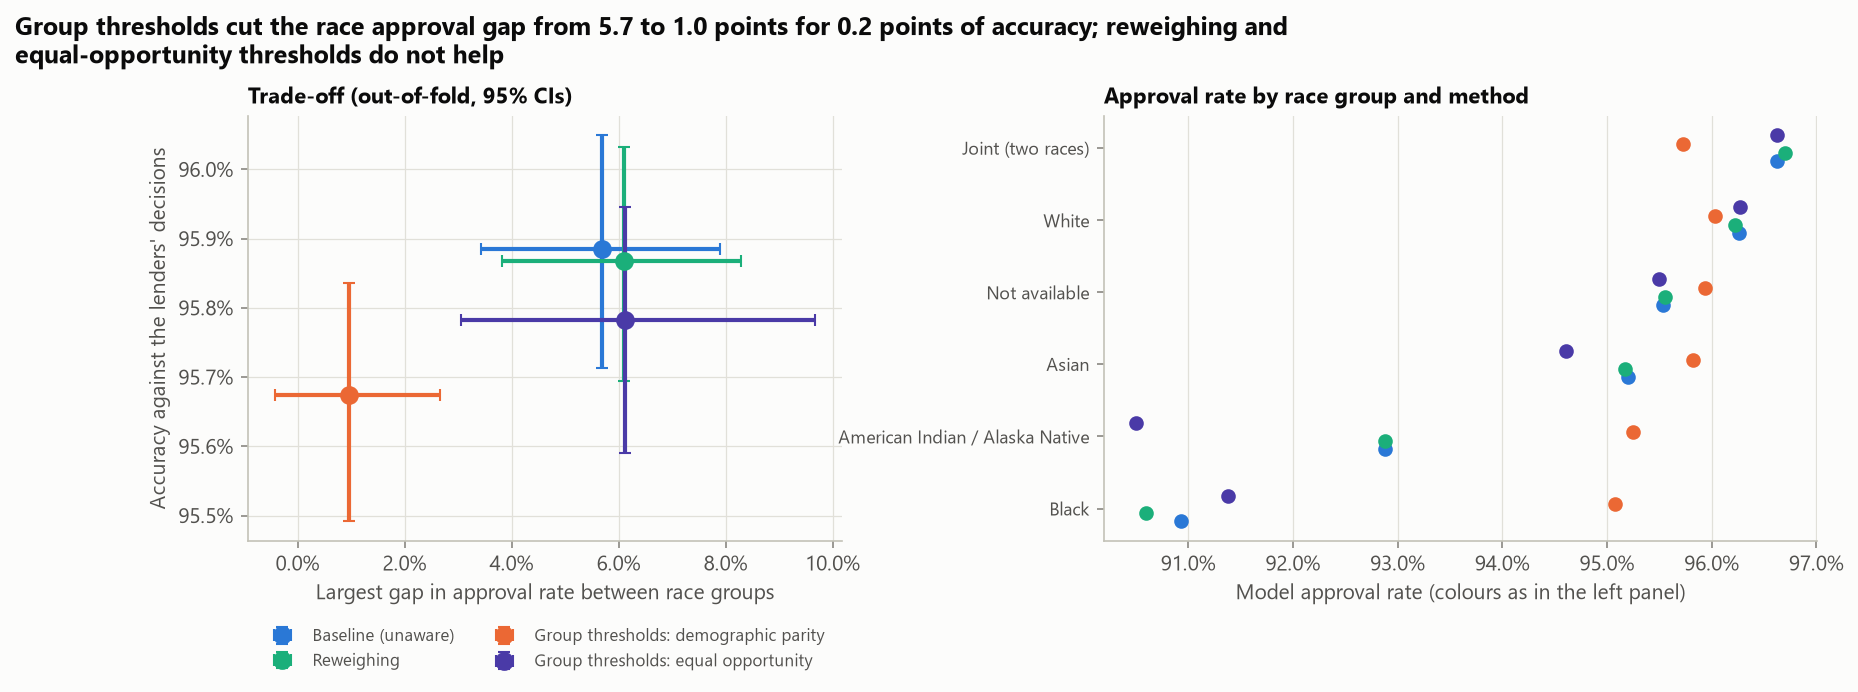

In [20]:
display(Image(FIG / '07_mitigation.png'))

## 5. Observational context: adjusted odds ratios

Logistic regressions of denial on group membership, first alone, then with the reported application fields as
controls (DTI and CLTV buckets, income, loan size, product, channel, county), then adding lender dummies. Standard
errors are heteroskedasticity-robust (HC1). Controlling for the reported fields moves the Black-White odds ratio
from 2.09 to 1.22 (CI 0.92-1.63), while the American Indian / Alaska Native (2.48 -> 2.09), Hispanic (1.95 -> 1.31)
and Asian (1.31 -> 1.36) odds ratios stay clearly above 1. These agree with the calibration gaps of the ML model.
Female applicants are denied at the same rate as male applicants with or without controls.

In [21]:
odds = pd.read_csv(RES / 'adjusted_odds_ratios.csv')
odds.pivot_table(index=['attribute', 'group'], columns='specification', values='odds_ratio').round(3)

specification                              Application controls  Application controls + lender  Unadjusted
attribute group                                                                                           
age       25-34                                           0.719                          0.716       0.743
          45-54                                           0.884                          0.893       0.946
          55-64                                           0.803                          0.827       0.835
          65-74                                           0.614                          0.629       0.605
          <25                                             0.835                          0.872       1.075
          >74                                             0.722                          0.781       0.710
ethnicity Hispanic or Latino                              1.307                          1.392       1.948
          Joint (Hispanic and not)                        0.891                          0.882       0.863
          Not available                                   1.244                          1.252       1.227
race      American Indian / Alaska Native                 2.088                          2.099       2.484
          Asian                                           1.363                          1.273       1.309
          Black                                           1.225                          1.173       2.093
          Joint (two races)                               0.949                          0.991       0.835
          Not available                                   1.226                          1.184       1.206
          Other minority races                            1.760                          1.547       1.958
sex       Female                                          0.958                          0.972       1.004
          Joint (male and female)                         0.722                          0.741       0.617
          Not available                                   0.805                          0.864       0.925

In [22]:
odds[['attribute', 'group', 'specification', 'n', 'odds_ratio', 'ci_low', 'ci_high', 'p_value', 'n_params', 'converged']]

,attribute,group,specification,n,odds_ratio,ci_low,ci_high,p_value,n_params,converged
0,race,American Indian / Alaska Native,Unadjusted,337,2.4839,1.8427,3.3482,2.3394e-09,7,True
1,race,Asian,Unadjusted,3397,1.3091,1.1539,1.4852,2.8851e-05,7,True
2,race,Black,Unadjusted,893,2.0931,1.7178,2.5504,2.3639e-13,7,True
3,race,Joint (two races),Unadjusted,1333,0.8346,0.6605,1.0546,1.2991e-01,7,True
4,race,Not available,Unadjusted,7923,1.2065,1.1015,1.3215,5.2951e-05,7,True
5,race,Other minority races,Unadjusted,175,1.9575,1.2495,3.0667,3.3611e-03,7,True
6,race,American Indian / Alaska Native,Application controls,337,2.0885,1.4192,3.0734,1.8688e-04,63,True
7,race,Asian,Application controls,3397,1.3629,1.1447,1.6227,5.0548e-04,63,True
8,race,Black,Application controls,893,1.2249,0.9201,1.6307,1.6468e-01,63,True
9,race,Joint (two races),Application controls,1333,0.9490,0.6895,1.3060,7.4786e-01,63,True


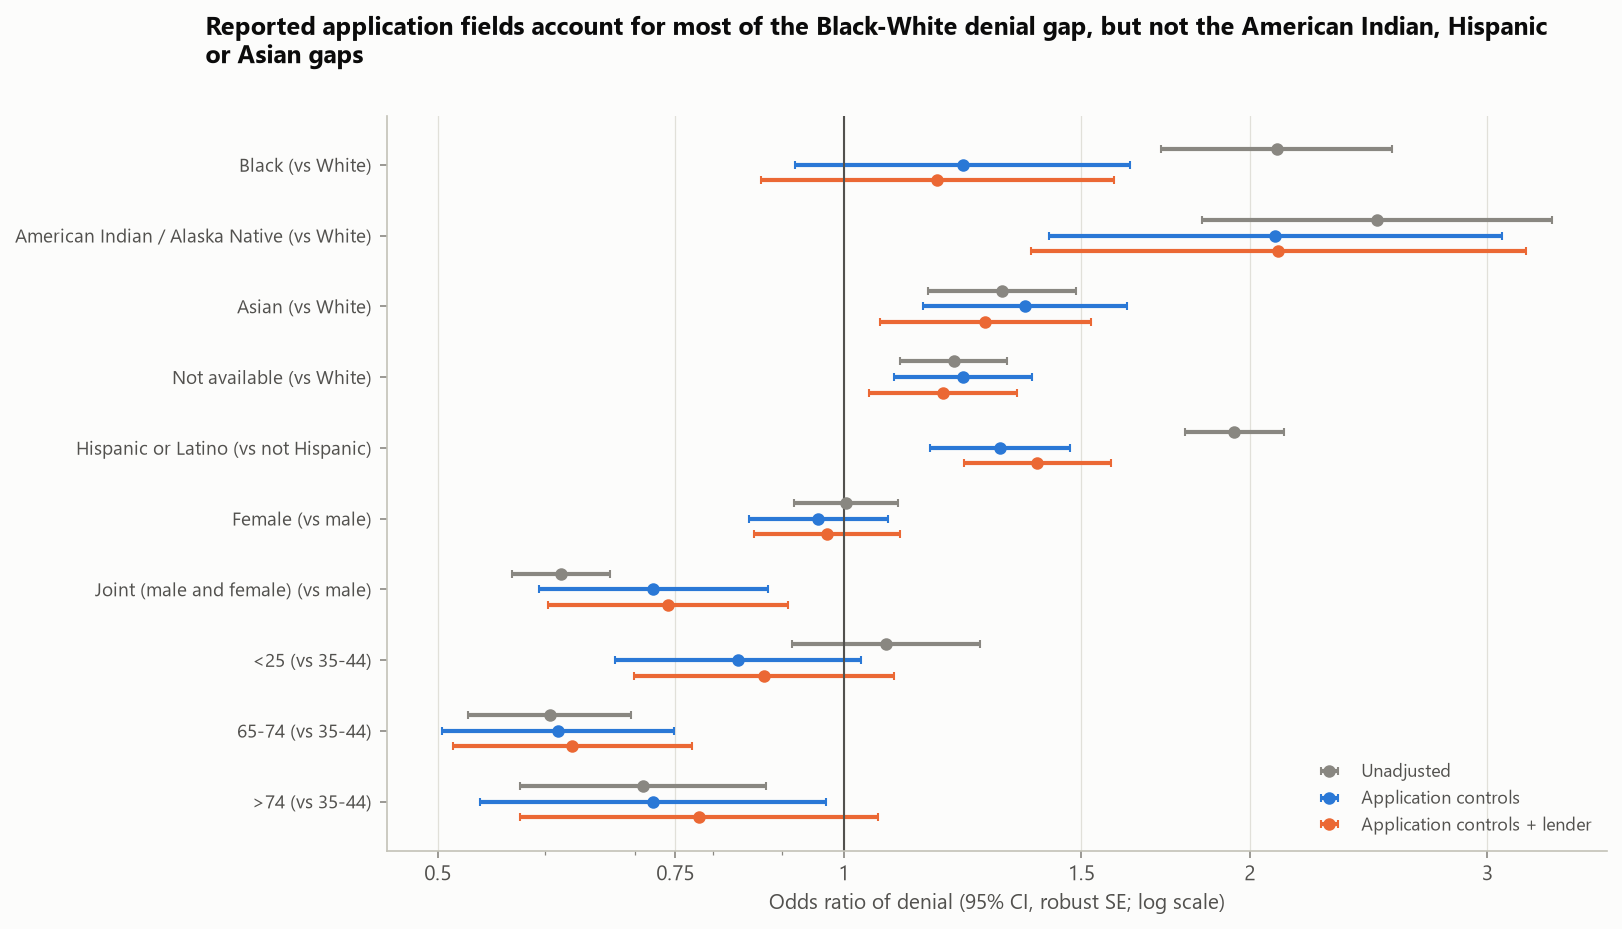

In [23]:
display(Image(FIG / '08_odds_ratios.png'))

### Proxy check and feature ablation

Leaving protected attributes out does not remove the group information: the model's inputs predict Black vs White
applicants with AUC 0.75, Hispanic vs not with 0.78 and age 62+ with 0.78 (sex only 0.62). The census-tract
minority share, which is excluded as an input for this reason, reaches 0.71 and 0.74 on its own. In the ablation,
debt-to-income is the one feature group the model cannot do without (ROC AUC -0.064 without it); removing the
missing-value flags costs 0.003.

In [24]:
pd.read_csv(RES / 'proxy_auc.csv')

,target,test_rows,positive_share,auc_model_features,auc_tract_minority_share_only,auc_tract_minority_share_either_direction
0,Black (vs White),6870,0.0261,0.7464,0.7097,0.7097
1,Hispanic or Latino (vs not),7596,0.1987,0.7827,0.7447,0.7447
2,Female (vs male),5063,0.3938,0.6178,0.4999,0.5001
3,Age 62 or older,9498,0.1919,0.7790,0.3291,0.6709


In [25]:
pd.read_csv(RES / 'ablation.csv')[['feature_set', 'n_features', 'roc_auc', 'ap', 'log_loss', 'roc_auc_change', 'ap_change']]

,feature_set,n_features,roc_auc,ap,log_loss,roc_auc_change,ap_change
0,All features,29,0.8900,0.6676,0.1483,0.0000,0.0000
1,Without debt-to-income,28,0.8258,0.4981,0.1899,-0.0642,-0.1696
2,"Without collateral (LTV, value)",27,0.8694,0.6332,0.1570,-0.0206,-0.0344
3,Without income and loan size,25,0.8819,0.6429,0.1549,-0.0081,-0.0247
4,Without missing fields,23,0.8869,0.6610,0.1502,-0.0032,-0.0067
5,Without lender,28,0.8695,0.6547,0.1539,-0.0205,-0.0129
6,Without underwriting channel,26,0.8712,0.6396,0.1556,-0.0189,-0.0280
7,Without loan terms,23,0.8840,0.6585,0.1501,-0.0061,-0.0092
8,Without location,24,0.8922,0.6721,0.1473,0.0022,0.0045
9,Without co-applicant,28,0.8865,0.6667,0.1492,-0.0035,-0.0009


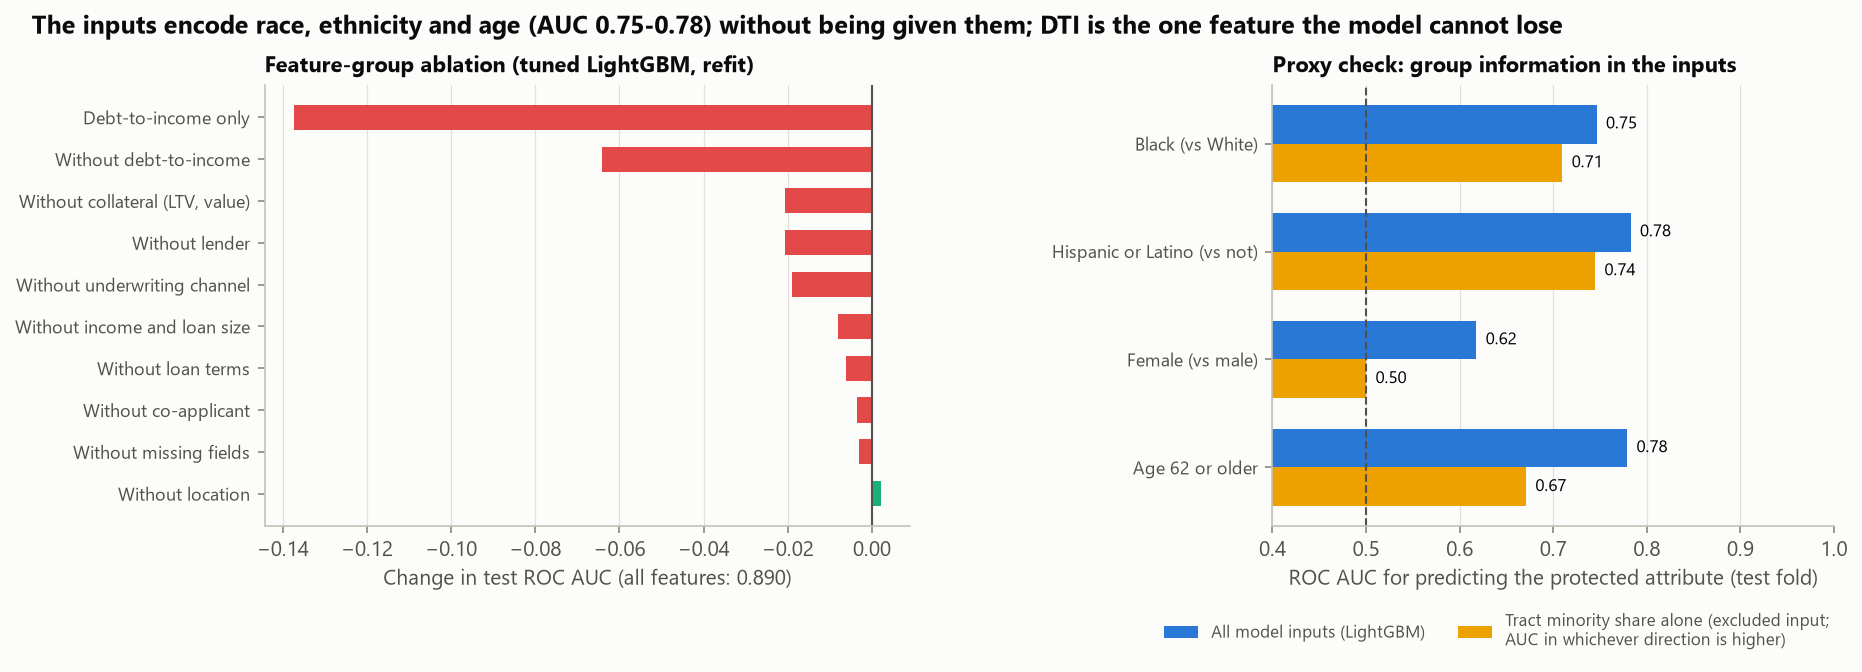

In [26]:
display(Image(FIG / '09_proxy_and_ablation.png'))

## 6. Explanations

### Global SHAP

TreeSHAP values come from LightGBM's own implementation and match the `shap` library's TreeExplainer exactly on 200
rows. The lender has the largest mean |SHAP| (lenders' denial rates differ a lot), followed by DTI and collateral,
but for denied applications the push towards denial comes mostly from DTI (mean SHAP +2.19 log-odds vs +0.25 for
the lender).

In [27]:
pd.read_csv(RES / 'shap_check.csv')

,rows,max_abs_diff,error,additivity_max_abs_err
0,200,0,NaN,1.4655e-14


In [28]:
pd.read_csv(RES / 'shap_importance.csv').head(15)

,feature,group,mean_abs_shap,mean_shap_denied,mean_shap_approved
0,lender,Lender,0.4941,0.2469,-0.0161
1,dti,Debt-to-income,0.3937,2.1877,-0.1858
2,property_value_k,"Collateral (LTV, value)",0.2076,0.0758,-0.0232
3,cltv,"Collateral (LTV, value)",0.1955,0.1006,-0.0072
4,aus,Underwriting channel,0.1597,0.1284,-0.0266
5,tract_housing_age,Location,0.0840,0.0040,-0.0075
6,tract_owner_share,Location,0.0786,0.0090,0.0014
7,property_value_missing,Missing fields,0.0677,0.1778,-0.0194
8,income_k,Income and loan size,0.0606,0.1520,-0.0102
9,loan_to_income,Income and loan size,0.0595,0.0914,-0.0056


In [29]:
pd.read_csv(RES / 'shap_group_importance.csv')

,group,mean_abs_shap
0,Lender,0.4941
1,Debt-to-income,0.3937
2,"Collateral (LTV, value)",0.3156
3,Underwriting channel,0.1695
4,Location,0.1551
5,Income and loan size,0.1293
6,Missing fields,0.0897
7,Co-applicant,0.0518
8,Loan terms,0.0508


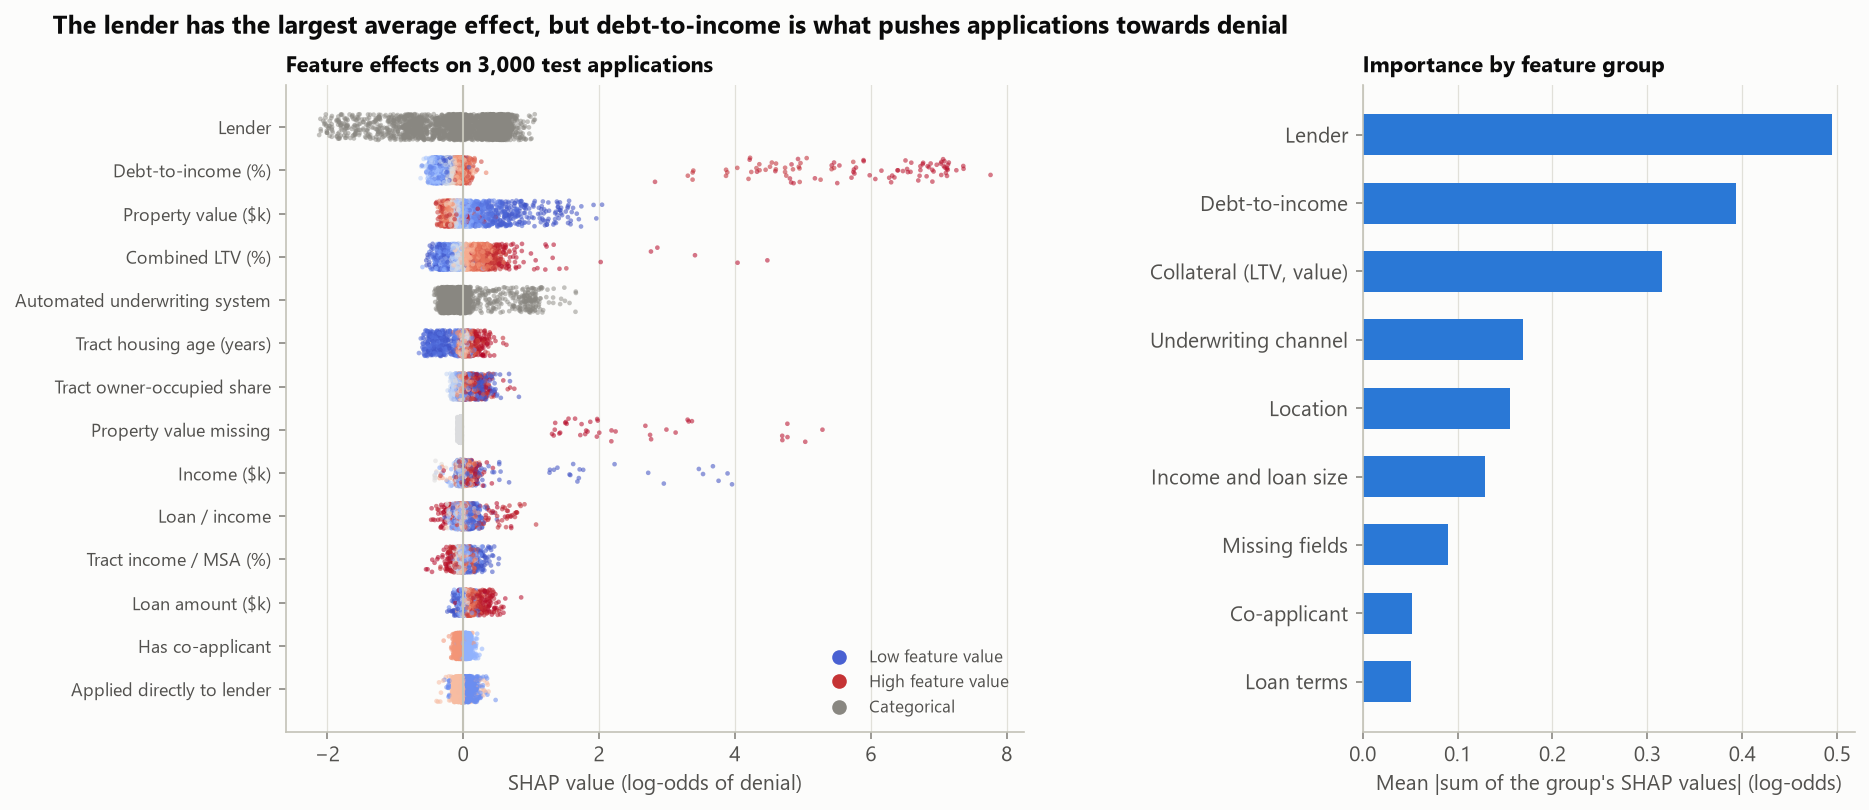

In [30]:
display(Image(FIG / '03_shap_global.png'))

### SHAP against the lender's stated denial reason

HMDA reports up to four denial reasons per denied application. They are never model inputs, which makes them a
check on the explanations: for each out-of-fold denial, the feature group with the largest SHAP push towards denial
is compared with the lender's first reason. SHAP points to DTI for 82% of the 1,406 DTI denials (12% for other
reasons), to collateral for 50% of collateral denials (8% otherwise) and to the missing-value flags for 38% of
'application incomplete' denials (3% otherwise). Credit-history denials, which HMDA's fields cannot see, spread
across groups.

In [31]:
pd.read_csv(RES / 'denial_reasons.csv')

,reason,first_reason,any_reason,share_first
0,Debt-to-income ratio,1406,1580,0.4015
1,Collateral,514,558,0.1468
2,Application incomplete,444,462,0.1268
3,Unverifiable information,271,398,0.0774
4,Credit history,268,336,0.0765
5,Other,258,369,0.0737
6,Insufficient cash,245,443,0.0700
7,Employment history,93,150,0.0266
8,Mortgage insurance denied,3,4,0.0009


In [32]:
pd.read_csv(RES / 'reason_match.csv')

,reported_reason,expected_group,n_denials,match_rate,match_rate_other_reasons,lift
0,Debt-to-income ratio,Debt-to-income,1406,0.8236,0.1174,7.0175
1,Collateral,"Collateral (LTV, value)",514,0.4981,0.0773,6.4424
2,Insufficient cash,"Collateral (LTV, value)",245,0.1918,0.1351,1.4200
3,Application incomplete,Missing fields,444,0.3761,0.0343,10.9542


In [33]:
ct = pd.read_csv(RES / 'reason_crosstab.csv').set_index('reported_reason')
(ct.drop(columns='n_denials').div(ct.n_denials, axis=0)).round(2).assign(n=ct.n_denials)

,Debt-to-income,"Collateral (LTV, value)",Income and loan size,Missing fields,Lender,Underwriting channel,Loan terms,Location,Co-applicant,n
reported_reason,,,,,,,,,,
Application incomplete,0.04,0.06,0.02,0.38,0.33,0.14,0.01,0.01,0.01,444
Collateral,0.04,0.50,0.02,0.03,0.22,0.11,0.01,0.06,0.02,514
Credit history,0.25,0.19,0.01,0.09,0.21,0.19,0.04,0.01,0.00,268
Debt-to-income ratio,0.82,0.02,0.06,0.02,0.04,0.02,0.01,0.01,0.00,1406
Employment history,0.42,0.09,0.04,0.09,0.20,0.10,0.02,0.01,0.03,93
Insufficient cash,0.11,0.19,0.07,0.01,0.34,0.17,0.02,0.06,0.04,245
Mortgage insurance denied,0.33,0.33,0.00,0.00,0.33,0.00,0.00,0.00,0.00,3
Other,0.11,0.14,0.05,0.10,0.34,0.20,0.02,0.02,0.02,258
Unverifiable information,0.18,0.12,0.09,0.02,0.31,0.20,0.01,0.03,0.03,271


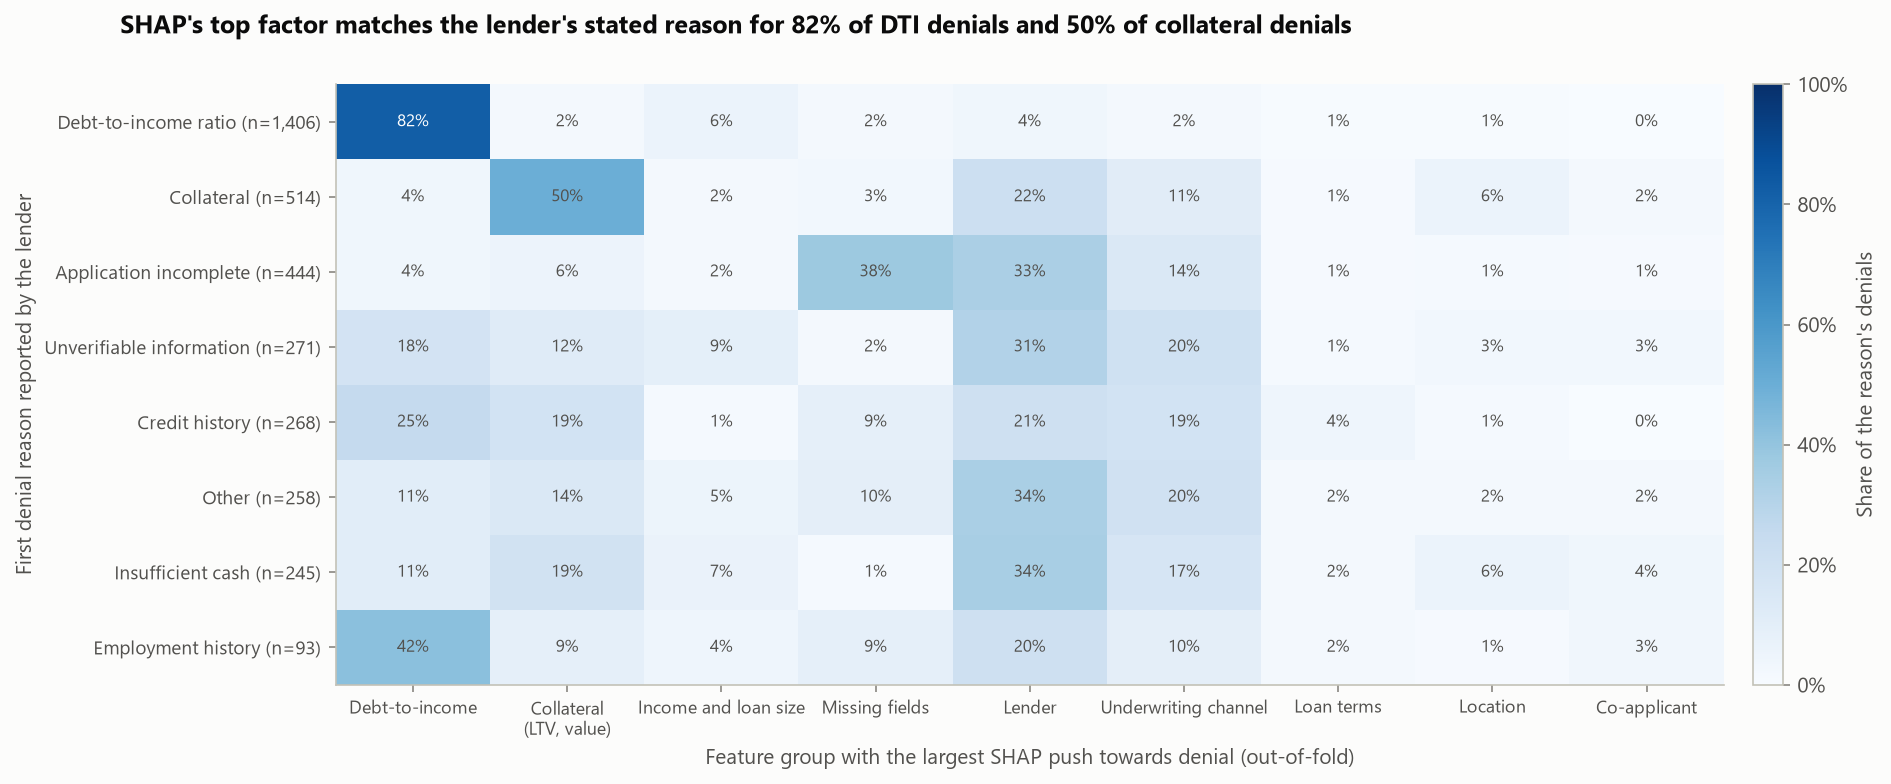

In [34]:
display(Image(FIG / '04_reason_codes.png'))

### SHAP vs LIME on 30 test applications

LIME (5,000 perturbations, quartile discretisation, categorical features sampled from training frequencies) was run
on 30 test applications: 10 flagged denials, 10 near the threshold and 10 approvals, each twice with different
seeds. LIME agrees with itself on the top feature in all 30 cases, but agrees with SHAP in only 1 of 30. The reason is
systematic: LIME ranks 'property value reported' first in every case. For an indicator that is 0 for 99% of
applicants, LIME's local surrogate reports the large effect of switching it, while SHAP weights that effect by how
rarely the value differs from the background. With the six missing-value flags excluded from both rankings, the
top features agree in 18 of 30 cases. The two methods answer different questions, and an adverse-action reason
should not be taken from either without checking which question it answers.

In [35]:
pd.read_csv(RES / 'explainer_agreement_summary.csv')

,comparison,k,top_k_overlap,sign_agreement,rank_corr_abs,same_top_feature
0,LIME seed 0 vs seed 1,1,1.0000,1.0000,0.6630,1.0000
1,LIME seed 0 vs seed 1,3,0.7444,0.9889,0.6630,1.0000
2,LIME seed 0 vs seed 1,5,0.6200,0.9683,0.6630,1.0000
3,SHAP vs LIME,1,0.0333,1.0000,-0.0045,0.0333
4,SHAP vs LIME,3,0.2556,1.0000,-0.0045,0.0333
5,SHAP vs LIME,5,0.2267,1.0000,-0.0045,0.0333
6,"SHAP vs LIME, missing-value flags excluded",1,0.6000,1.0000,0.1315,0.6000
7,"SHAP vs LIME, missing-value flags excluded",3,0.3333,1.0000,0.1315,0.6000
8,"SHAP vs LIME, missing-value flags excluded",5,0.3800,0.9833,0.1315,0.6000


In [36]:
pd.read_csv(RES / 'explainer_agreement_by_stratum.csv').pivot_table(index=['comparison', 'stratum'], columns='k',
                                                                     values='top_k_overlap').round(2)

k                                                                   1     3     5
comparison                                 stratum                               
LIME seed 0 vs seed 1                      Approved, not flagged  1.0  0.67  0.66
                                           Denied, flagged        1.0  0.80  0.58
                                           Near the threshold     1.0  0.77  0.62
SHAP vs LIME                               Approved, not flagged  0.0  0.17  0.20
                                           Denied, flagged        0.0  0.33  0.24
                                           Near the threshold     0.1  0.27  0.24
SHAP vs LIME, missing-value flags excluded Approved, not flagged  0.2  0.23  0.30
                                           Denied, flagged        1.0  0.43  0.48
                                           Near the threshold     0.6  0.33  0.36

In [37]:
pd.read_csv(RES / 'lime_cases.csv')[['stratum', 'denied', 'p_denial', 'reported_reason', 'shap_top3', 'lime_top3',
                                    'lime_seed1_top3']].head(12)

,stratum,denied,p_denial,reported_reason,shap_top3,lime_top3,lime_seed1_top3
0,"Denied, flagged",1,0.9882,Debt-to-income ratio,dti (+); loan_to_income (+); cltv (+),property_value_missing (-); dti (+); interest_only (-),property_value_missing (-); dti (+); negative_amortization (+)
1,"Denied, flagged",1,0.7524,Credit history,dti (+); lender (+); tract_housing_age (-),property_value_missing (-); dti (+); loan_term_missing (-),property_value_missing (-); dti (+); loan_term_missing (-)
2,"Denied, flagged",1,0.9883,Debt-to-income ratio,dti (+); loan_to_income (+); lender (-),property_value_missing (-); dti (+); interest_only (-),property_value_missing (-); dti (+); interest_only (-)
3,"Denied, flagged",1,0.9669,Debt-to-income ratio,dti (+); loan_to_income (+); aus (+),property_value_missing (-); dti (+); dti_missing (-),property_value_missing (-); dti (+); location_missing (-)
4,"Denied, flagged",1,0.9855,Debt-to-income ratio,dti (+); income_k (+); lender (+),property_value_missing (-); dti (+); interest_only (-),property_value_missing (-); dti (+); interest_only (-)
5,"Denied, flagged",1,0.9636,Debt-to-income ratio,dti (+); lender (-); property_value_k (+),property_value_missing (-); dti (+); negative_amortization (-),property_value_missing (-); dti (+); balloon (-)
6,"Denied, flagged",1,0.8189,Debt-to-income ratio,dti (+); income_k (+); lender (-),property_value_missing (-); dti (+); balloon (+),property_value_missing (-); dti (+); balloon (+)
7,"Denied, flagged",1,0.9112,Debt-to-income ratio,dti (+); interest_only (+); aus (+),property_value_missing (-); dti (+); loan_term_missing (+),property_value_missing (-); dti (+); interest_only (+)
8,"Denied, flagged",1,0.9817,Employment history,dti (+); loan_to_income (+); credit_model (+),property_value_missing (-); dti (+); location_missing (-),property_value_missing (-); dti (+); negative_amortization (+)
9,"Denied, flagged",1,0.9876,Debt-to-income ratio,dti (+); loan_to_income (+); loan_amount_k (+),property_value_missing (-); dti (+); loan_term_missing (-),property_value_missing (-); dti (+); dti_missing (-)


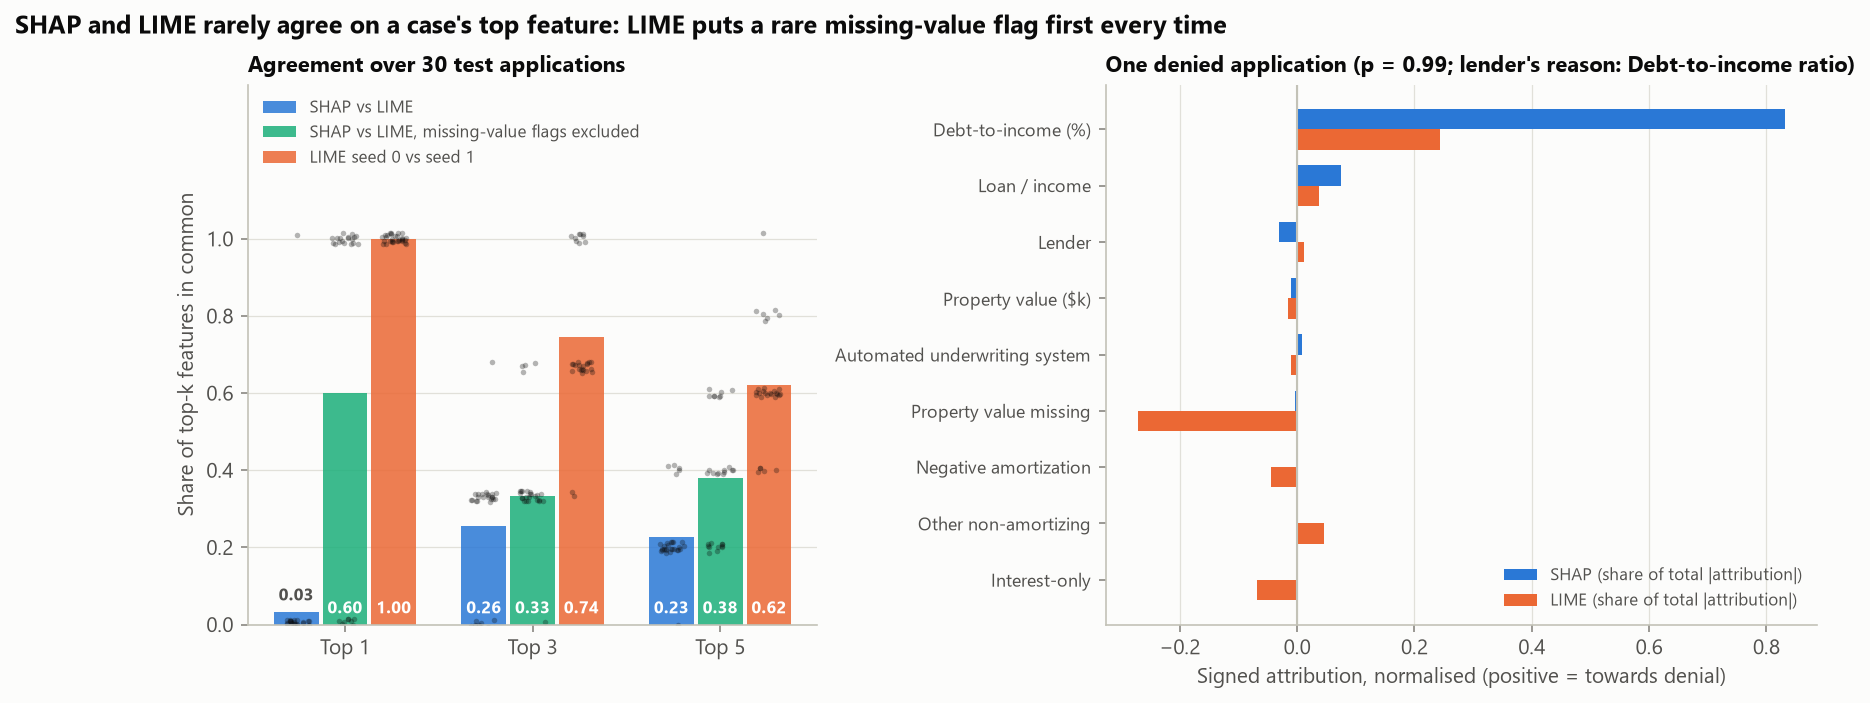

In [38]:
display(Image(FIG / '05_shap_vs_lime.png'))

## 7. Limitations

- **Observational data without credit scores.** Gaps in denial rates or in calibration are associations; they
  cannot separate discrimination from unreported risk factors. 'Equal opportunity' uses the lenders' historical
  approvals as ground truth, which would carry any bias in those decisions.
- **One state, one year, two outcomes.** Withdrawn, incomplete and pre-approval records are excluded, which is a
  selection step before the outcome.
- **Small groups.** American Indian / Alaska Native (337) and other minority races (175) have wide intervals.
- **Explanation checks are limited.** LIME ran on 30 cases; the denial-reason comparison maps reasons to feature
  groups with a fixed rule in code (`REASON_TO_GROUP`) and uses only the first reason.
- **Tuning budgets were small** (30 / 20 / 10 Optuna trials; one seed per model).

Run time and package versions:

In [39]:
{k: v for k, v in meta.items() if k in ['stage_seconds', 'total_seconds', 'versions']}

{'stage_seconds': {'data': 2.0,
  'models': 0.0,
  'crossfit': 0.0,
  'audit': 6.4,
  'mitigation': 7.2,
  'odds_ratios': 4.6,
  'proxy': 1.6,
  'ablation': 6.1,
  'explain': 1.7},
 'total_seconds': 58.0,
 'versions': {'python': '3.12.10',
  'numpy': '2.5.3',
  'pandas': '2.3.3',
  'scikit-learn': '1.9.1',
  'lightgbm': '4.7.0',
  'xgboost': '3.4.1',
  'catboost': '1.2.10',
  'optuna': '5.0.0',
  'shap': '0.53.0',
  'lime': '0.2.0.1',
  'fairlearn': '0.14.0'}}